In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

### Load data

In [22]:
PROJECT_ROOT = Path("..").resolve()
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

sales = pd.read_csv(
    RAW_DATA_DIR / "sales_train_evaluation.csv"
)

calendar = pd.read_csv(
    RAW_DATA_DIR / "calendar.csv"
)

calendar["date"] = pd.to_datetime(calendar["date"])

sales_columns = sorted(
    [c for c in sales.columns if c.startswith("d_")],
    key=lambda x: int(x.split("_")[1])
)

# Aggregate across all item-store series for each day.
daily_sales = sales[sales_columns].sum(axis=0)

daily_sales = daily_sales.rename("total_sales").reset_index()

daily_sales.columns = ["d", "total_sales"]

daily_sales["day_num"] = (
    daily_sales["d"].str.replace("d_", "", regex=False).astype(int)
)

daily_sales = daily_sales.merge(
    calendar[["d", "date", "weekday", "month", "year"]],
    on="d",
    how="left",
    validate="one_to_one"
)

display(daily_sales.head())

,d,total_sales,day_num,date,weekday,month,year
0,d_1,32631,1,2011-01-29,Saturday,1,2011
1,d_2,31749,2,2011-01-30,Sunday,1,2011
2,d_3,23783,3,2011-01-31,Monday,1,2011
3,d_4,25412,4,2011-02-01,Tuesday,2,2011
4,d_5,19146,5,2011-02-02,Wednesday,2,2011


### Daily Sales Trend

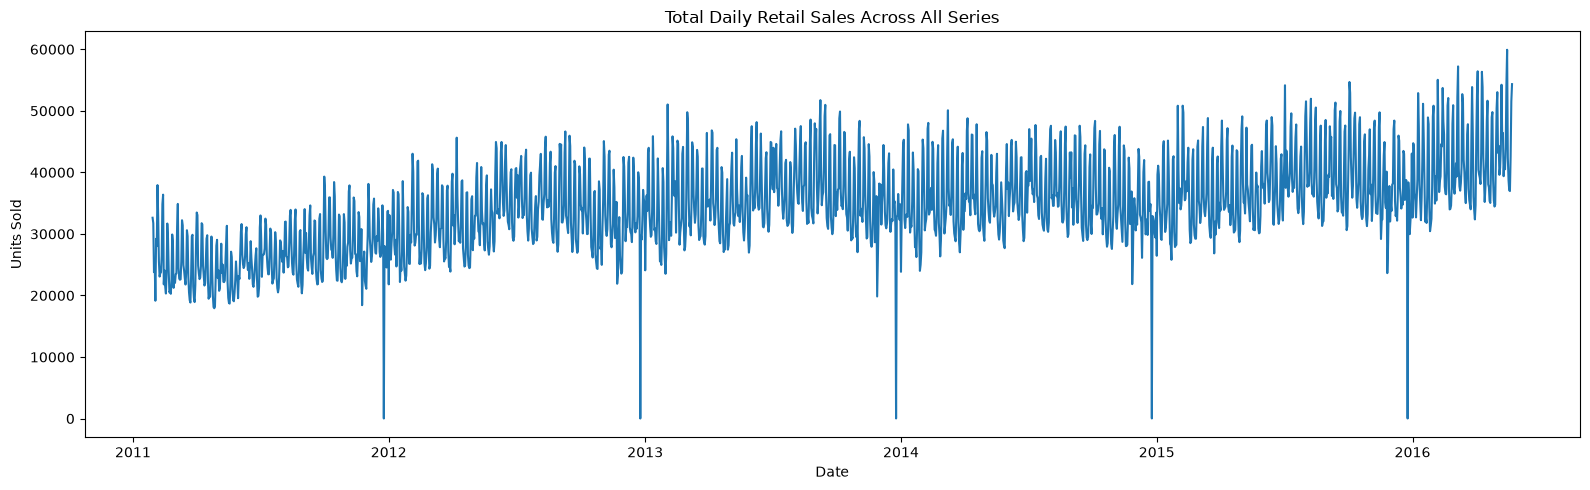

In [23]:
plt.figure(figsize=(16, 5))

plt.plot(
    daily_sales["date"],
    daily_sales["total_sales"]
)

plt.title("Total Daily Retail Sales Across All Series")
plt.xlabel("Date")
plt.ylabel("Units Sold")

plt.tight_layout()
plt.show()

### Sales by State

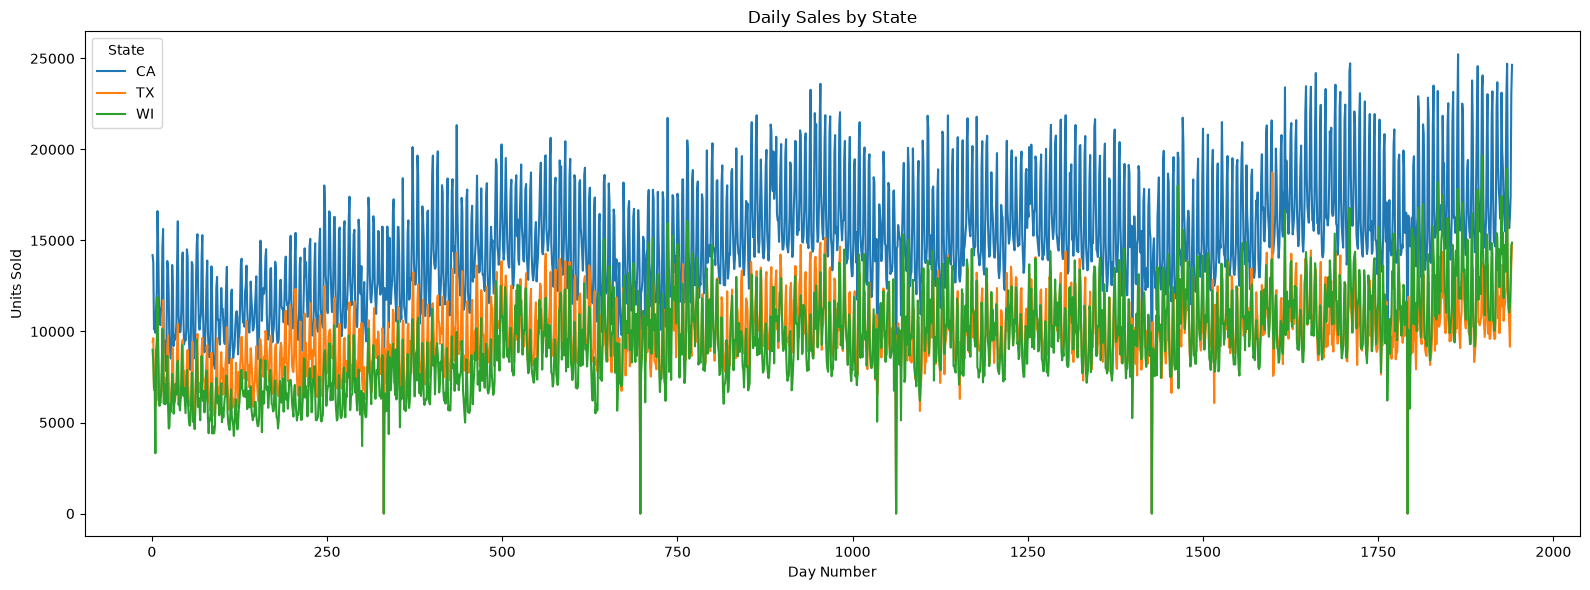

In [24]:
state_sales = sales.groupby("state_id")[sales_columns].sum()

plt.figure(figsize=(16, 6))

for state in state_sales.index:
    plt.plot(
        range(1, len(sales_columns) + 1),
        state_sales.loc[state],
        label=state
    )

plt.title("Daily Sales by State")
plt.xlabel("Day Number")
plt.ylabel("Units Sold")
plt.legend(title="State")

plt.tight_layout()
plt.show()

### Sales by Stores

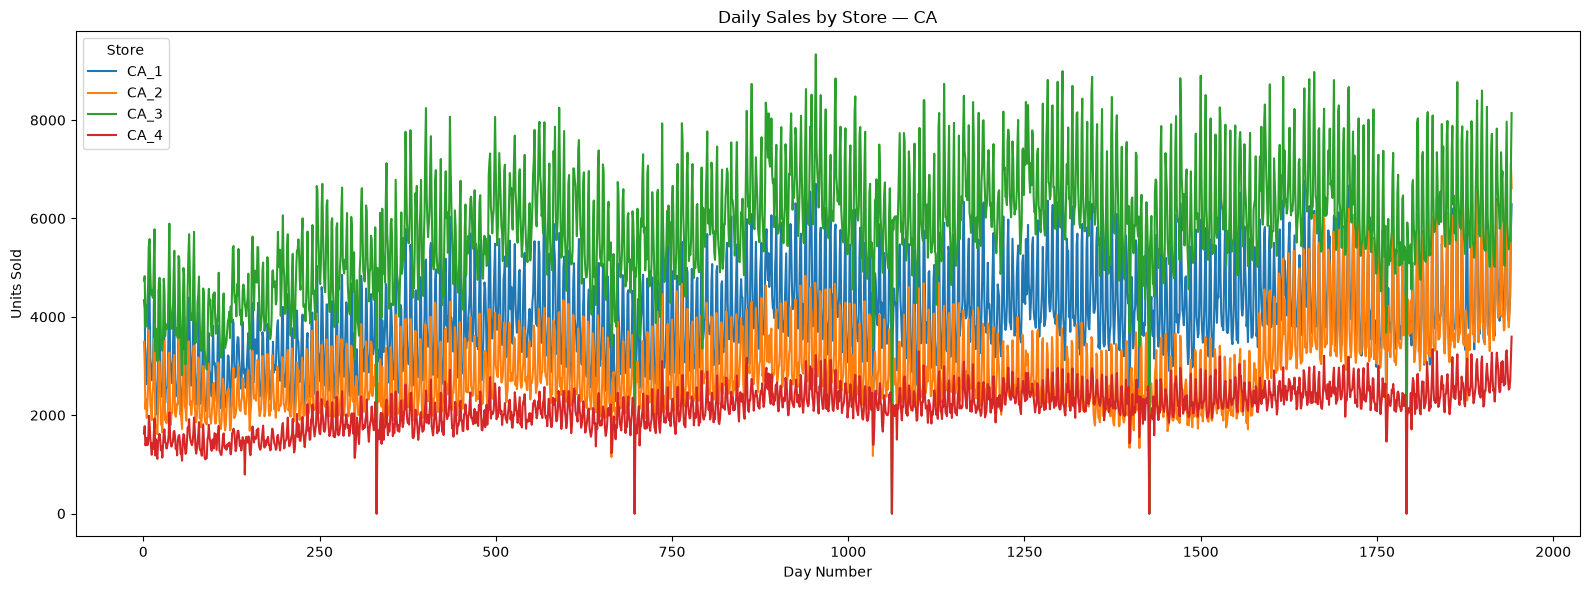

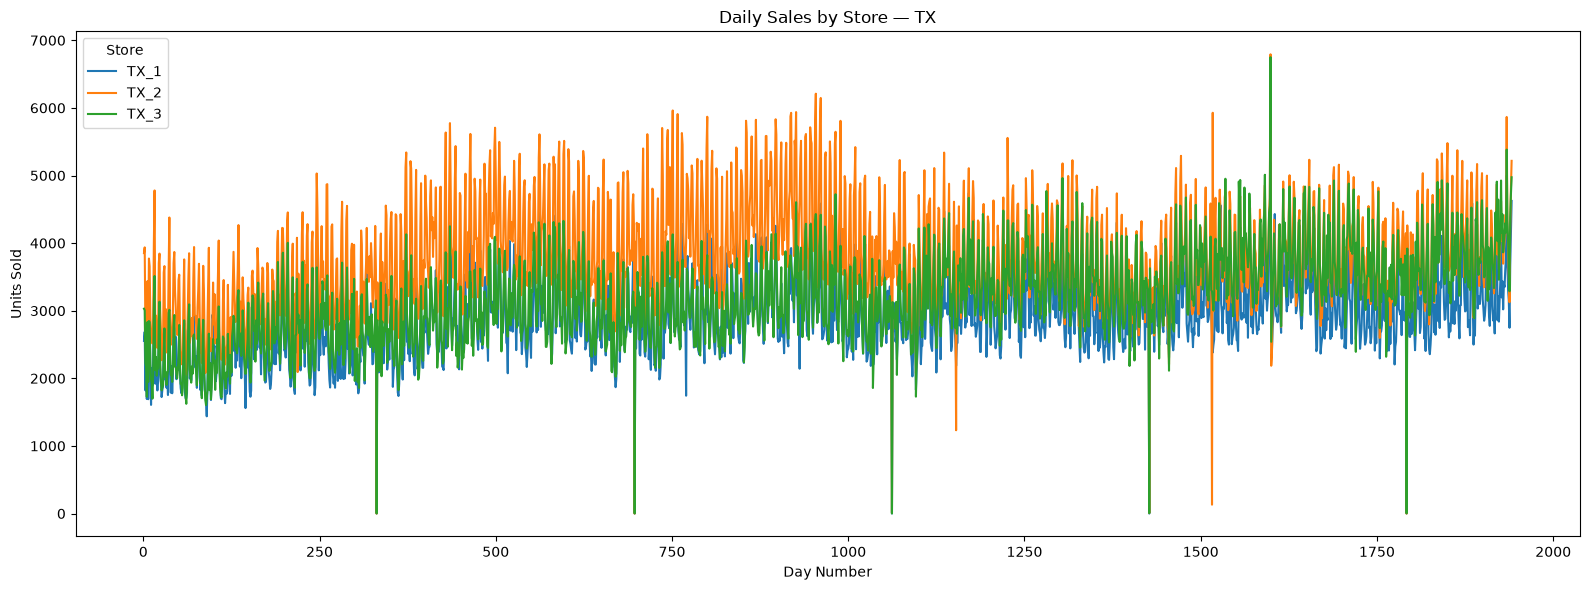

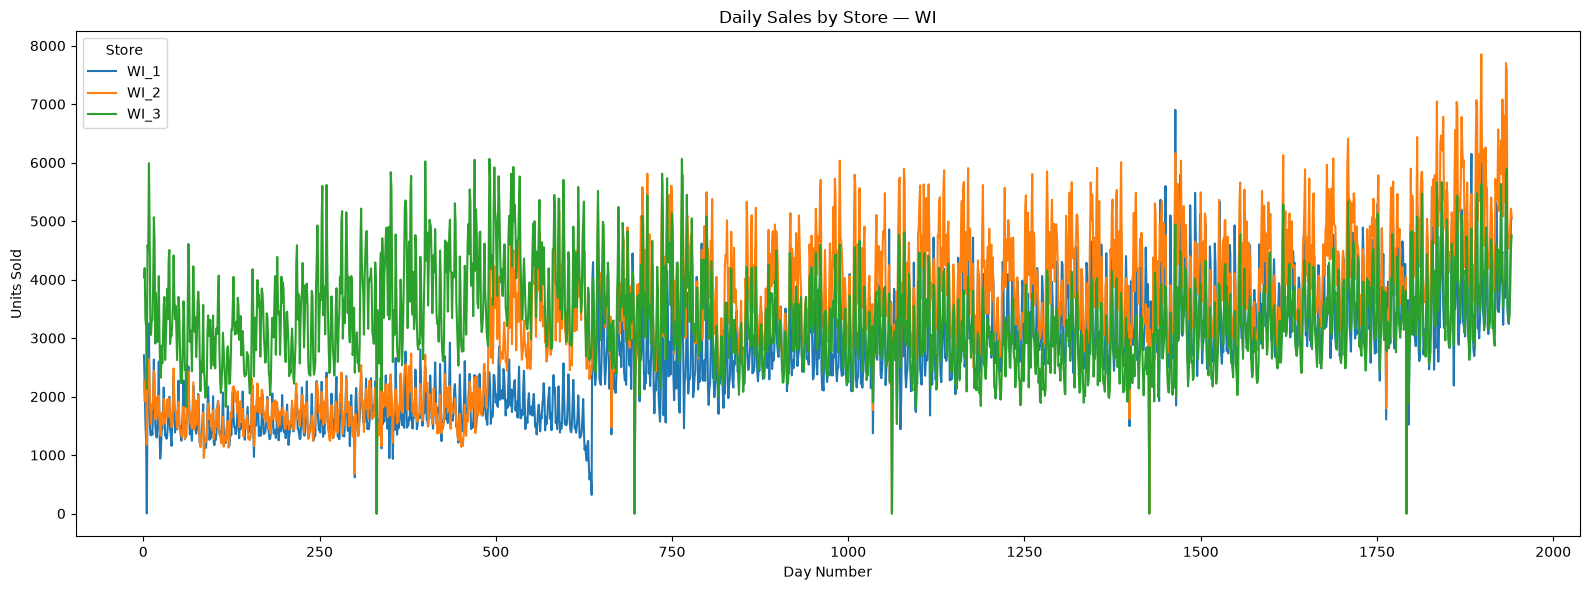

In [25]:
state_store_sales = sales.groupby(["state_id", "store_id"])[sales_columns].sum()

states = sales["state_id"].unique()

for state in sorted(states):
    state_data = state_store_sales.loc[state]

    plt.figure(figsize=(16, 6))

    for store in state_data.index:
        plt.plot(
            range(1, len(sales_columns) + 1),
            state_data.loc[store],
            label=store
        )

    plt.title(f"Daily Sales by Store — {state}")
    plt.xlabel("Day Number")
    plt.ylabel("Units Sold")
    plt.legend(title="Store")

    plt.tight_layout()
    plt.show()

### Sales by Category

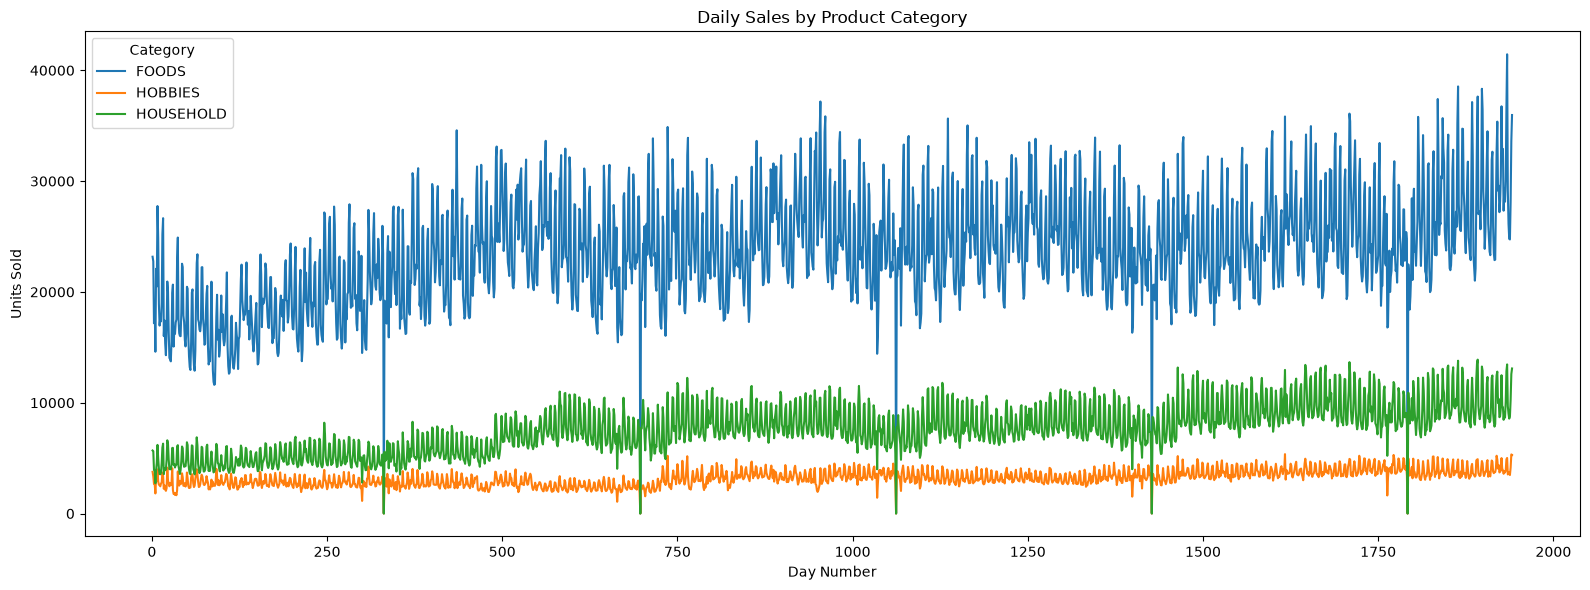

In [26]:
category_sales = sales.groupby("cat_id")[sales_columns].sum()

plt.figure(figsize=(16, 6))

for category in category_sales.index:
    plt.plot(
        range(1, len(sales_columns) + 1),
        category_sales.loc[category],
        label=category
    )

plt.title("Daily Sales by Product Category")
plt.xlabel("Day Number")
plt.ylabel("Units Sold")
plt.legend(title="Category")

plt.tight_layout()
plt.show()

### Weekday Seasonality

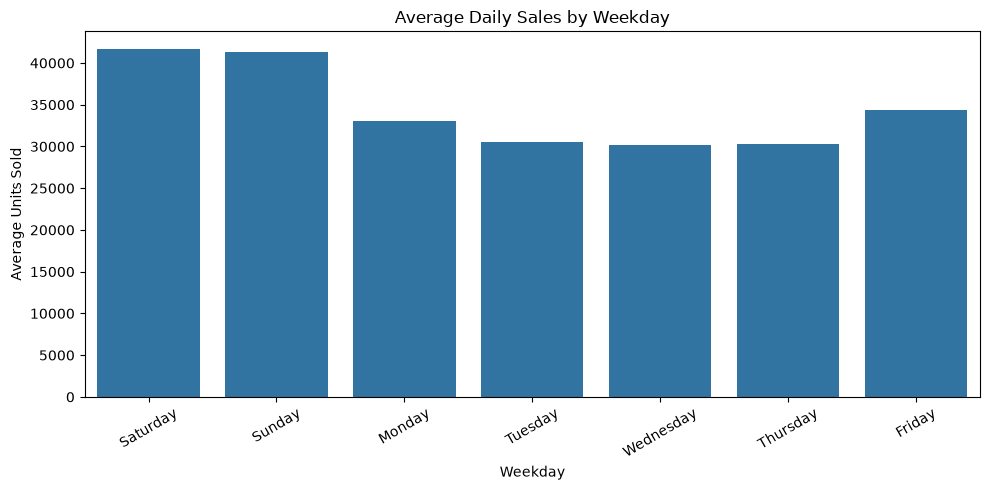

In [27]:
weekday_sales = daily_sales.groupby(
    "weekday"
)["total_sales"].mean()

weekday_order = [
    "Saturday",
    "Sunday",
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday"
]

weekday_sales = weekday_sales.reindex(weekday_order)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=weekday_sales.index,
    y=weekday_sales.values
)

plt.title("Average Daily Sales by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


### Monthly Seasonality

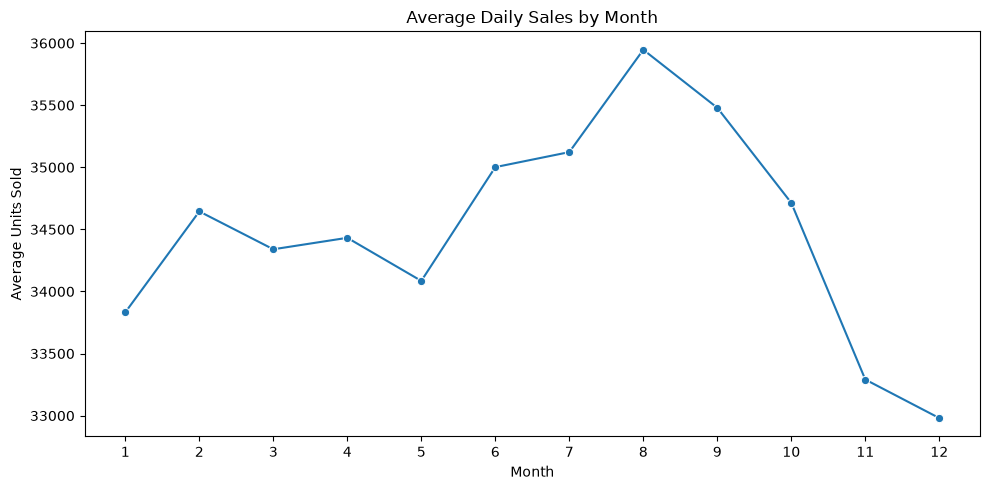

In [28]:
monthly_sales = daily_sales.groupby(
    "month"
)["total_sales"].mean()

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=monthly_sales.index,
    y=monthly_sales.values,
    marker="o"
)

plt.title("Average Daily Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Units Sold")
plt.xticks(range(1, 13))

plt.tight_layout()
plt.show()

## Zero-Sales Analysis

### Overall zero-sales proportion

In [29]:
sales_matrix = sales[sales_columns].to_numpy(dtype=np.float32)

total_observations = sales_matrix.size
zero_observations = np.count_nonzero(sales_matrix == 0)

zero_sales_share = zero_observations / total_observations

print(f"Total observations: {total_observations:,}")
print(f"Zero-sales observations: {zero_observations:,}")
print(f"Zero-sales share: {zero_sales_share:.2%}")

Total observations: 59,181,090
Zero-sales observations: 40,241,819
Zero-sales share: 68.00%


### Zero-sales share by category

In [30]:
category_zero_results = []

for category, group in sales.groupby("cat_id"):

    matrix = group[sales_columns].to_numpy(dtype=np.float32)

    total = matrix.size
    zero_count = np.count_nonzero(matrix == 0)

    category_zero_results.append({
        "category": category,
        "total_observations": total,
        "zero_observations": zero_count,
        "zero_sales_share": zero_count / total
    })

category_zero_df = pd.DataFrame(category_zero_results)

display(
    category_zero_df.sort_values(
        "zero_sales_share",
        ascending=False
    )
)

,category,total_observations,zero_observations,zero_sales_share
1,HOBBIES,10966650,8460679,0.771492
2,HOUSEHOLD,20322270,14551192,0.716022
0,FOODS,27892170,17229948,0.617734


### Zero-sales share by demand class

In [31]:
series_classes = pd.read_parquet(PROJECT_ROOT / "data" / "metadata" / "series_classes.parquet")

zero_by_class = (
    series_classes
    .groupby("demand_class")
    .agg(
        series_count=("id", "count"),
        total_active_days=("active_period", "sum"),
        zero_active_days=("zero_days_active", "sum")
    )
)

zero_by_class["zero_sales_share_active"] = (
    zero_by_class["zero_active_days"]
    / zero_by_class["total_active_days"]
)

display(zero_by_class)

,series_count,total_active_days,zero_active_days,zero_sales_share_active
demand_class,,,,
erratic,868,1465327,244761,0.167035
intermittent,22150,33241987,22276566,0.670133
lumpy,5564,8979433,4793167,0.533794
smooth,1908,2983607,416589,0.139626


## Pre-launch periods and first price week

### Identify first price week

In [32]:
sell_prices = pd.read_csv(
    RAW_DATA_DIR / "sell_prices.csv"
)

first_price_week = (
    sell_prices
    .groupby(["item_id", "store_id"], as_index=False)
    ["wm_yr_wk"]
    .min()
)

first_price_week = first_price_week.rename(
    columns={"wm_yr_wk": "first_price_week"}
)

display(first_price_week.head())

,item_id,store_id,first_price_week
0,FOODS_1_001,CA_1,11101
1,FOODS_1_001,CA_2,11101
2,FOODS_1_001,CA_3,11101
3,FOODS_1_001,CA_4,11101
4,FOODS_1_001,TX_1,11101


In [33]:
# Map the first price week to its first calendar day
week_start_dates = (
    calendar
    .groupby("wm_yr_wk", as_index=False)
    .agg(first_calendar_date=("date", "min"))
)

first_price_week = first_price_week.merge(
    week_start_dates,
    left_on="first_price_week",
    right_on="wm_yr_wk",
    how="left",
    validate="many_to_one"
)

first_price_week = first_price_week.drop(
    columns=["wm_yr_wk"]
)

display(first_price_week.head())

,item_id,store_id,first_price_week,first_calendar_date
0,FOODS_1_001,CA_1,11101,2011-01-29
1,FOODS_1_001,CA_2,11101,2011-01-29
2,FOODS_1_001,CA_3,11101,2011-01-29
3,FOODS_1_001,CA_4,11101,2011-01-29
4,FOODS_1_001,TX_1,11101,2011-01-29


### Compare First Sales and First Price

In [34]:
first_sales = series_classes[
    ["item_id", "store_id", "first_demand_day"]
].copy()

first_sales["first_sale_date"] = first_sales[
    "first_demand_day"
].map(
    lambda day: (
        calendar.loc[
            calendar["d"] == f"d_{int(day)}",
            "date"
        ].iloc[0]
        if pd.notna(day)
        else pd.NaT
    )
)

first_availability = first_sales.merge(
    first_price_week,
    on=["item_id", "store_id"],
    how="left",
    validate="one_to_one"
)

first_availability["days_between_price_and_sale"] = (
    first_availability["first_sale_date"]
    - first_availability["first_calendar_date"]
).dt.days

display(first_availability.head())

,item_id,store_id,first_demand_day,first_sale_date,first_price_week,first_calendar_date,days_between_price_and_sale
0,HOBBIES_1_001,CA_1,902,2013-07-18,11325,2013-07-13,5
1,HOBBIES_1_002,CA_1,144,2011-06-21,11121,2011-06-18,3
2,HOBBIES_1_003,CA_1,1106,2014-02-07,11401,2014-02-01,6
3,HOBBIES_1_004,CA_1,37,2011-03-06,11106,2011-03-05,1
4,HOBBIES_1_005,CA_1,113,2011-05-21,11117,2011-05-21,0


## SNAP and event analysis

### SNAP (Supplemental Nutrition Assistance Program)

SNAP is a US government food assistance programme that provides eligible low-income households with benefits to purchase food. In the M5 dataset, the calendar includes three SNAP indicators: `snap_CA`, `snap_TX`, and `snap_WI`, representing SNAP benefit availability in California, Texas, and Wisconsin, respectively.

A value of `1` indicates a SNAP day, while `0` indicates a non-SNAP day. These indicators are included to examine potential differences in retail sales patterns and serve as calendar features for demand forecasting.

### SNAP-day sales by state

,state,non_snap_avg_sales,snap_avg_sales
0,CA,14657.744812,15823.423437
1,TX,9543.856264,10643.512500
2,WI,8892.503459,10832.662500


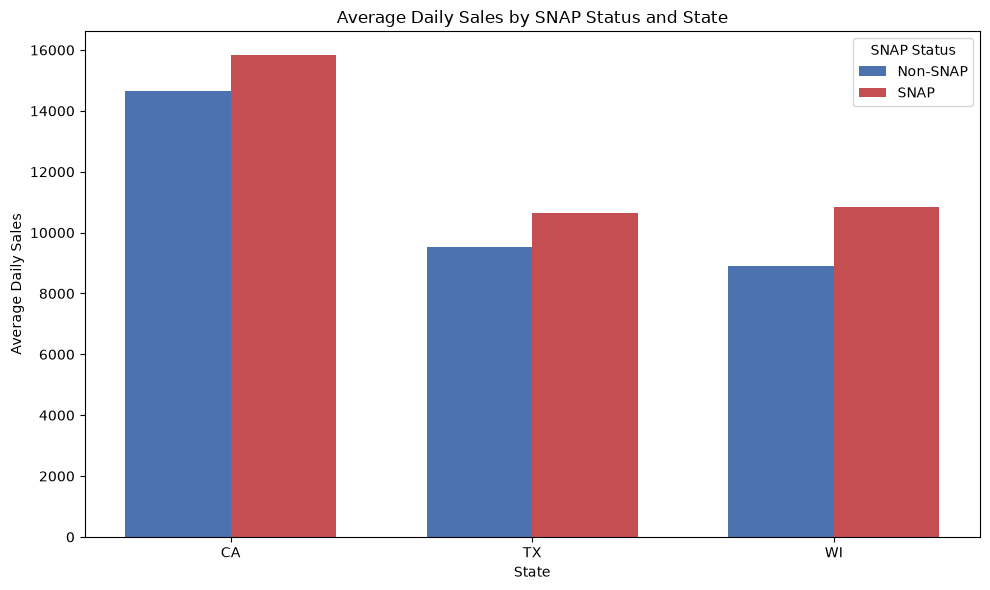

In [35]:
state_day_sales = (
    sales.groupby("state_id")[sales_columns]
    .sum()
    .T
    .reset_index()
)

state_day_sales.columns = ["d"] + list(
    state_day_sales.columns[1:]
)

state_day_sales = state_day_sales.merge(
    calendar[["d", "date", "snap_CA", "snap_TX", "snap_WI"]],
    on="d",
    how="left",
    validate="one_to_one"
)

state_snap_columns = {
    "CA": "snap_CA",
    "TX": "snap_TX",
    "WI": "snap_WI"
}

snap_results = []

for state, snap_column in state_snap_columns.items():

    comparison = state_day_sales.copy()

    comparison["snap_status"] = comparison[snap_column].map({
        0: "Non-SNAP",
        1: "SNAP"
    })

    means = comparison.groupby(
        "snap_status"
    )[state].mean()

    snap_results.append({
        "state": state,
        "non_snap_avg_sales": means.get("Non-SNAP", np.nan),
        "snap_avg_sales": means.get("SNAP", np.nan)
    })

snap_comparison = pd.DataFrame(snap_results)

display(snap_comparison)

plt.figure(figsize=(10, 6))
x = np.arange(len(snap_comparison))
width = 0.35
plt.bar(
    x - width / 2,
    snap_comparison["non_snap_avg_sales"],
    width,
    label="Non-SNAP",
    color="#4c72b0"
)
plt.bar(
    x + width / 2,
    snap_comparison["snap_avg_sales"],
    width,
    label="SNAP",
    color="#c44e52"
)
plt.xlabel("State")
plt.ylabel("Average Daily Sales")
plt.title("Average Daily Sales by SNAP Status and State")
plt.xticks(x, snap_comparison["state"])
plt.legend(title="SNAP Status")
plt.tight_layout()
plt.show()

In [36]:
calendar["has_event"] = (
    calendar["event_name_1"].notna()
    | calendar["event_name_2"].notna()
)

event_sales = daily_sales.merge(
    calendar[["d", "has_event"]],
    on="d",
    how="left",
    validate="one_to_one"
)

event_comparison = (
    event_sales
    .groupby("has_event")["total_sales"]
    .agg(["mean", "median", "std", "count"])
)

display(event_comparison)

,mean,median,std,count
has_event,,,,
False,34609.336511,33817.0,7202.360245,1783
True,33029.911392,33956.5,9502.940436,158
